# NASAA V4 — Degradation-Aware Sensor Selection with GRU (DA-GRU)

**Dataset:** NASA C-MAPSS, FD001  
**Task:** Remaining Useful Life (RUL) prediction  
**Baseline:** the original GRU pipeline from V2  
**Proposed contribution:** a Degradation-Aware Sensor Index (DASI) used to rank and select sensor channels before the same GRU architecture.

## Experimental story

1. Explore the C-MAPSS data and construct the capped RUL target.
2. Perform sensor-level EDA and causal, per-engine feature engineering.
3. Calculate DASI from **training engines only** using monotonicity, trendability and prognosability.
4. Compare the original V2 hand-selected 14-sensor GRU with a DASI-selected 14-sensor GRU.
5. Keep the GRU architecture, window length, train/validation engines, validation cutoffs and training settings the same.
6. Evaluate the final models on the official test set only after validation-based decisions are complete.

> **Research integrity:** DASI is a proposed composite sensor-ranking heuristic. The notebook tests whether it improves this GRU setup; it does not assume an improvement. Do not call it a proven novel method until the controlled results support that claim.

### Important methodology choices

- The split is by **engine ID**, never by individual rows.
- DASI is fitted on training engines only. Validation and official test sensor values do not influence the ranking.
- The official test RUL file is held back until final evaluation.
- The GRU architecture is unchanged from V2: a two-layer GRU followed by the same regression head. **No attention is used.**
- Rolling/lag/EWMA features are generated and visualized as part of feature engineering. The GRU itself receives selected raw sensor sequences, matching the V2 design: the GRU learns temporal dependencies from ordered readings.

---

## 1. Imports and reproducibility

In [1]:
import copy
import json
import random
import joblib
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# ------------------------- Reproducibility -------------------------
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# ------------------------- Runtime -------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ------------------------- Plot style -------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 300

# ------------------------- Experiment configuration -------------------------
SUBSET = "FD001"
RUL_CAP = 125
WINDOW_SIZE = 30
TOP_K_SENSORS = 14
VALIDATION_RUL_POINTS = [20, 50, 80, 110]
BATCH_SIZE = 128
MAX_EPOCHS = 50
PATIENCE = 8
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.2
LEARNING_RATE = 0.002
WEIGHT_DECAY = 1e-4

# Change this path to the folder containing train_FD001.txt,
# test_FD001.txt, and RUL_FD001.txt.
# Example Colab path: Path("/content/drive/MyDrive/CMaps")
DATA_DIR = Path(r"D:\ML_project\extracted\CMaps")

OUTPUT_DIR = Path("outputs_DA_GRU")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR.resolve())

Device: cpu
Output directory: D:\ML_project\outputs_DA_GRU


## 2. Load NASA C-MAPSS FD001

The three expected files are `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt`. If using Colab, mount Google Drive first and update `DATA_DIR`.

In [2]:
columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

read_options = {"sep": r"\s+", "header": None, "names": columns}

train_path = DATA_DIR / f"train_{SUBSET}.txt"
test_path = DATA_DIR / f"test_{SUBSET}.txt"
rul_path = DATA_DIR / f"RUL_{SUBSET}.txt"

for path in (train_path, test_path, rul_path):
    if not path.exists():
        raise FileNotFoundError(
            f"File not found: {path}\n"
            "Update DATA_DIR so it points to the folder containing the three C-MAPSS files."
        )

train_df = pd.read_csv(train_path, **read_options)
test_df = pd.read_csv(test_path, **read_options)
rul_df = pd.read_csv(rul_path, sep=r"\s+", header=None, names=["RUL"])

sensor_columns = [f"sensor_{i}" for i in range(1, 22)]
setting_columns = [f"op_setting_{i}" for i in range(1, 4)]
original_features = ["cycle"] + setting_columns + sensor_columns

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Official test RUL shape:", rul_df.shape)

display(train_df.head())
display(test_df.head())
display(rul_df.head())

Training shape: (20631, 26)
Test shape: (13096, 26)
Official test RUL shape: (100, 1)


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


,RUL
0,112
1,98
2,69
3,82
4,91


## 3. Data quality checks and RUL target construction

For each complete training engine, raw RUL equals its final observed cycle minus the current cycle. We use the same piecewise-linear target convention as V2: values above 125 are capped at 125.

The official test RUL file gives remaining life at the **last observed test cycle**. We use it only in the final test section.

In [3]:
# ------------------------- Data quality -------------------------
train_df = train_df.sort_values(["unit", "cycle"]).reset_index(drop=True)
test_df = test_df.sort_values(["unit", "cycle"]).reset_index(drop=True)

for name, frame in [("train", train_df), ("test", test_df)]:
    print(f"\\n{name.upper()} DATA")
    print("Missing values:", int(frame.isna().sum().sum()))
    print("Duplicate rows:", int(frame.duplicated().sum()))
    print("Unique engines:", frame["unit"].nunique())
    print("Cycle range:", int(frame["cycle"].min()), "to", int(frame["cycle"].max()))
    assert frame[["unit", "cycle"]].notna().all().all()

assert train_df.groupby("unit")["cycle"].apply(lambda x: x.is_monotonic_increasing).all()
assert len(rul_df) == test_df["unit"].nunique(), "Test engine count and RUL label count differ."

# ------------------------- Training labels -------------------------
train_df = train_df.sort_values(["unit", "cycle"]).reset_index(drop=True)
train_last_cycle = train_df.groupby("unit")["cycle"].max()
train_df["RUL_raw"] = train_df["unit"].map(train_last_cycle) - train_df["cycle"]
train_df["RUL"] = train_df["RUL_raw"].clip(upper=RUL_CAP)

print("\\nRaw training RUL summary:")
display(train_df["RUL_raw"].describe().to_frame())
print("Capped training RUL summary:")
display(train_df["RUL"].describe().to_frame())
display(train_df[["unit", "cycle", "RUL_raw", "RUL"]].head(10))

assert train_df["RUL"].min() == 0
assert train_df["RUL"].max() <= RUL_CAP

\nTRAIN DATA
Missing values: 0
Duplicate rows: 0
Unique engines: 100
Cycle range: 1 to 362
\nTEST DATA
Missing values: 0
Duplicate rows: 0
Unique engines: 100
Cycle range: 1 to 303
\nRaw training RUL summary:


,RUL_raw
count,20631.000000
mean,107.807862
std,68.880990
min,0.000000
25%,51.000000
50%,103.000000
75%,155.000000
max,361.000000


Capped training RUL summary:


,RUL
count,20631.000000
mean,86.829286
std,41.673699
min,0.000000
25%,51.000000
50%,103.000000
75%,125.000000
max,125.000000


,unit,cycle,RUL_raw,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


## 4. Exploratory data analysis (EDA)

These figures are designed to be reusable in the presentation. Each plot is also saved as a 300-DPI PNG under `outputs_DA_GRU/figures/`.

Saved: outputs_DA_GRU\figures\01_engine_life_and_rul_distribution.png


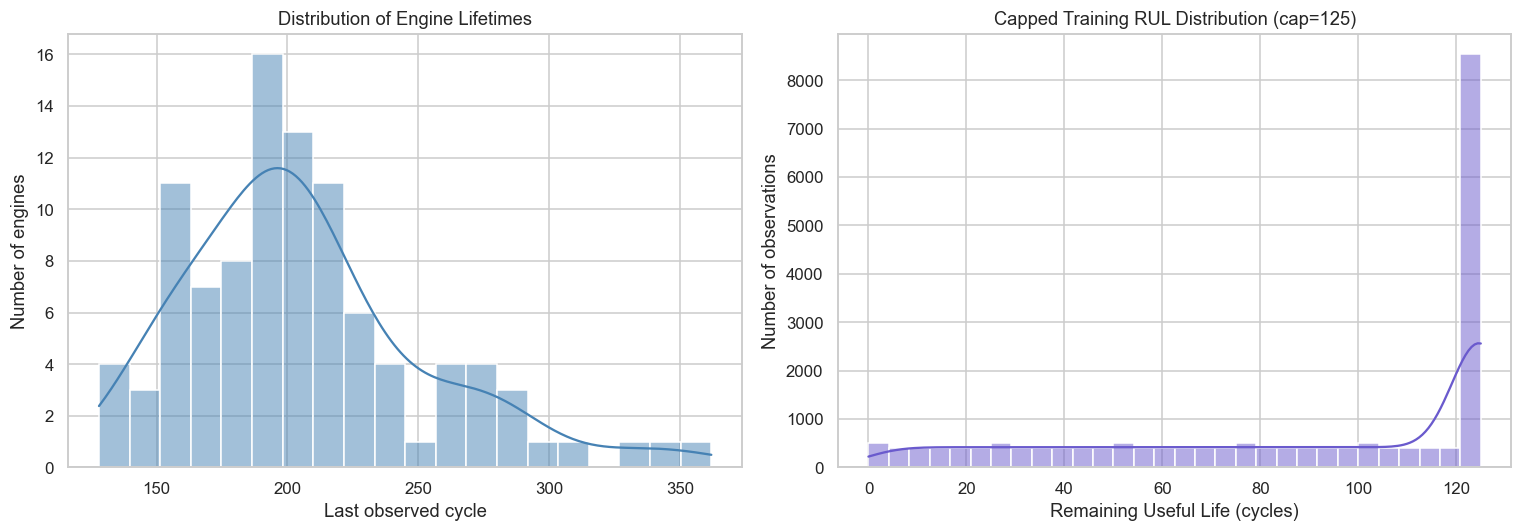

Saved: outputs_DA_GRU\figures\02_piecewise_rul_target.png


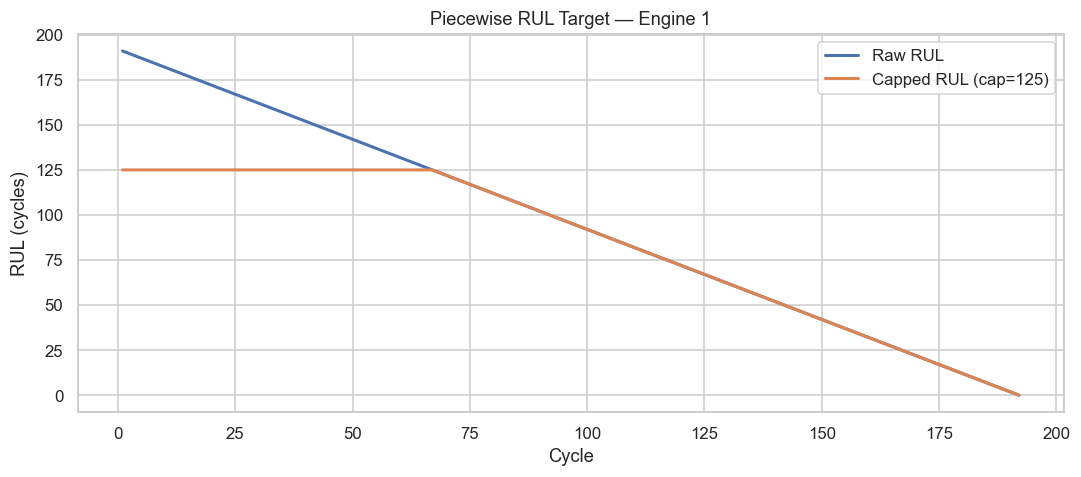

Saved: outputs_DA_GRU\figures\03_sensor_correlation_heatmap.png


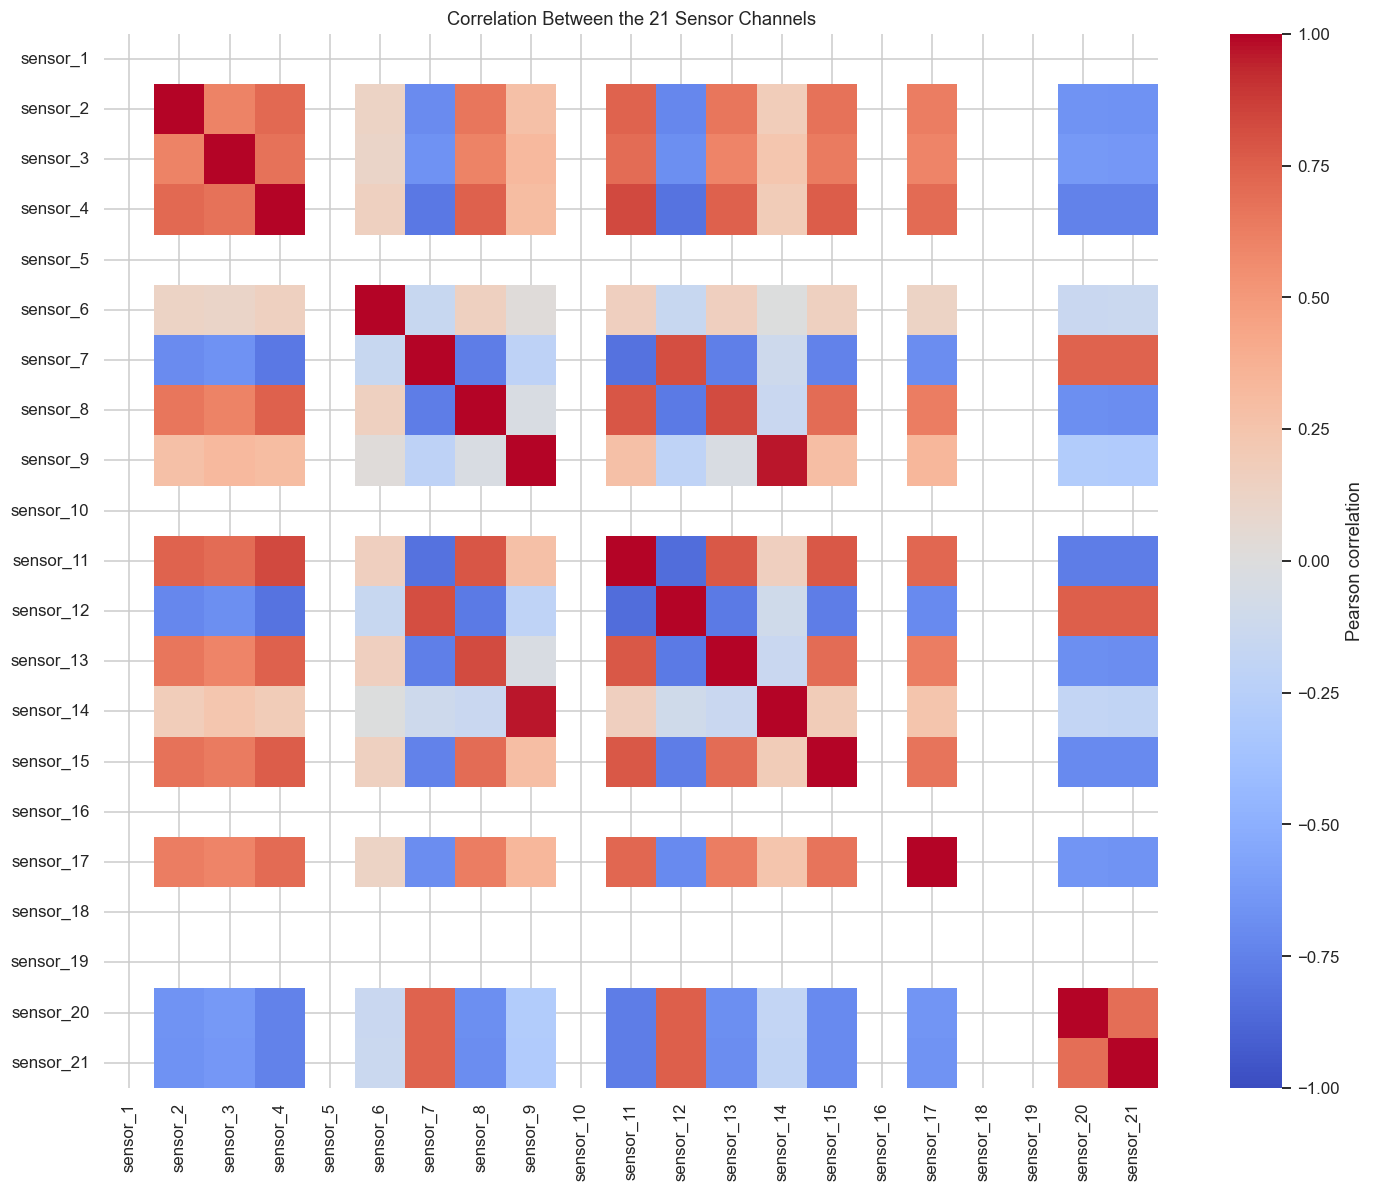

Saved: outputs_DA_GRU\figures\04_sensor_variability.png


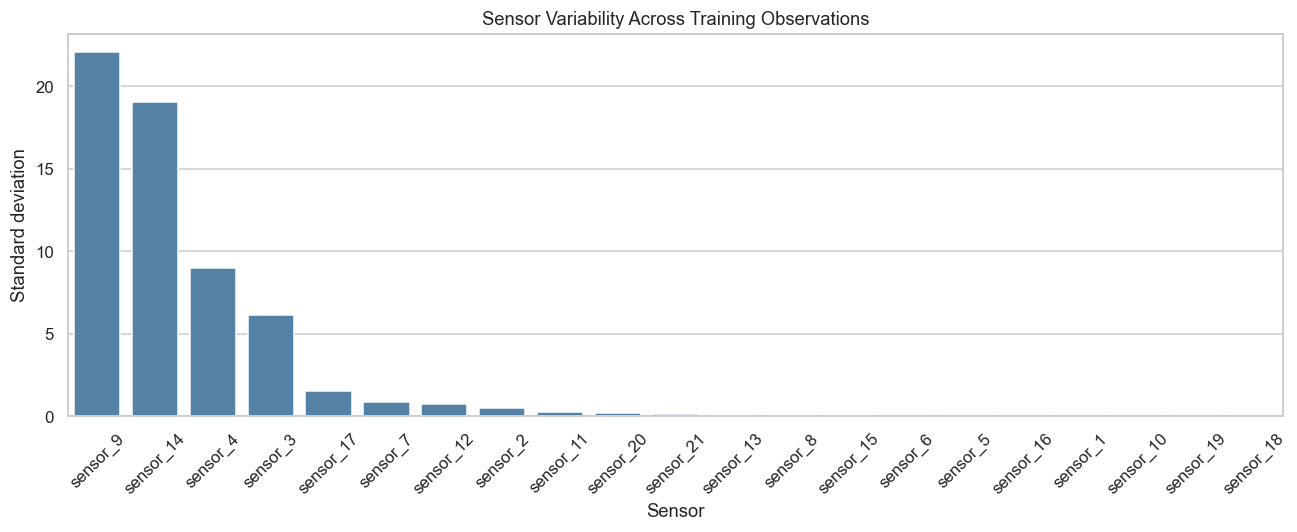

Engine count: 100
Sensor count: 21
Operating setting count: 3


In [4]:
def save_show(fig, filename):
    """Save a presentation-quality figure and display it in the notebook."""
    fig.tight_layout()
    save_path = FIGURE_DIR / filename
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    print("Saved:", save_path)
    plt.show()

# Figure 1: engine life and RUL target distributions
engine_life = train_df.groupby("unit")["cycle"].max()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(engine_life, bins=20, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of Engine Lifetimes")
axes[0].set_xlabel("Last observed cycle")
axes[0].set_ylabel("Number of engines")

sns.histplot(train_df["RUL"], bins=30, kde=True, color="slateblue", ax=axes[1])
axes[1].set_title(f"Capped Training RUL Distribution (cap={RUL_CAP})")
axes[1].set_xlabel("Remaining Useful Life (cycles)")
axes[1].set_ylabel("Number of observations")

save_show(fig, "01_engine_life_and_rul_distribution.png")

# Figure 2: raw and capped RUL for one representative engine
sample_unit = int(train_df["unit"].iloc[0])
sample_engine = train_df[train_df["unit"] == sample_unit]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(sample_engine["cycle"], sample_engine["RUL_raw"], label="Raw RUL", linewidth=2)
ax.plot(sample_engine["cycle"], sample_engine["RUL"], label=f"Capped RUL (cap={RUL_CAP})", linewidth=2)
ax.set_title(f"Piecewise RUL Target — Engine {sample_unit}")
ax.set_xlabel("Cycle")
ax.set_ylabel("RUL (cycles)")
ax.legend()
save_show(fig, "02_piecewise_rul_target.png")

# Figure 3: sensor correlation heatmap
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    train_df[sensor_columns].corr(),
    cmap="coolwarm", center=0, vmin=-1, vmax=1,
    square=True, ax=ax, cbar_kws={"label": "Pearson correlation"}
)
ax.set_title("Correlation Between the 21 Sensor Channels")
save_show(fig, "03_sensor_correlation_heatmap.png")

# Figure 4: sensor variability (useful for identifying almost-constant channels)
sensor_std = train_df[sensor_columns].std().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=sensor_std.index, y=sensor_std.values, color="steelblue", ax=ax)
ax.set_title("Sensor Variability Across Training Observations")
ax.set_xlabel("Sensor")
ax.set_ylabel("Standard deviation")
ax.tick_params(axis="x", rotation=45)
save_show(fig, "04_sensor_variability.png")

print("Engine count:", train_df["unit"].nunique())
print("Sensor count:", len(sensor_columns))
print("Operating setting count:", len(setting_columns))

## 5. Feature engineering

The following features are calculated **within each engine**, in cycle order:

- Rolling mean (5): local sensor level.
- Rolling standard deviation (5): local sensor variability.
- First difference: change since the previous cycle.
- Lag 1 and lag 3: recent historical readings.
- EWMA (span 5): smoothed recent sensor behaviour.

All transformations use the current and previous observations only. Grouping by engine prevents one engine's history from leaking into another engine.

As in V2, these engineered columns are created for EDA and feature-analysis. The GRU uses selected raw sensor sequences because recurrent layers already learn temporal patterns from ordered observations; this also keeps the baseline-vs-proposed comparison focused on the effect of sensor selection.

C:\Users\Adi\AppData\Local\Temp\ipykernel_28148\1539499576.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{col}_diff_1"] = grouped.diff(1)
C:\Users\Adi\AppData\Local\Temp\ipykernel_28148\1539499576.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{col}_lag_1"] = grouped.shift(1)
C:\Users\Adi\AppData\Local\Temp\ipykernel_28148\1539499576.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining 

Original sensor count: 21
Engineered feature count: 126
Training shape after feature engineering: (20631, 154)
Test shape after feature engineering: (13096, 152)


C:\Users\Adi\AppData\Local\Temp\ipykernel_28148\1539499576.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{col}_diff_1"] = grouped.diff(1)
C:\Users\Adi\AppData\Local\Temp\ipykernel_28148\1539499576.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{col}_lag_1"] = grouped.shift(1)
C:\Users\Adi\AppData\Local\Temp\ipykernel_28148\1539499576.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining 

,unit,cycle,sensor_2,sensor_2_rolling_mean_5,sensor_2_rolling_std_5,sensor_2_diff_1,sensor_2_lag_1,sensor_2_lag_3,sensor_2_ewma_5
0,1,1,641.82,641.820000,NaN,NaN,NaN,NaN,641.820000
1,1,2,642.15,641.985000,0.233345,0.33,641.82,NaN,641.930000
2,1,3,642.35,642.106667,0.267644,0.20,642.15,NaN,642.070000
3,1,4,642.35,642.167500,0.250117,0.00,642.35,641.82,642.163333
4,1,5,642.37,642.208000,0.234776,0.02,642.35,642.15,642.232222
5,1,6,642.10,642.264000,0.128374,-0.27,642.37,642.35,642.188148
6,1,7,642.48,642.330000,0.139463,0.38,642.10,642.35,642.285432
7,1,8,642.56,642.372000,0.174270,0.08,642.48,642.37,642.376955
8,1,9,642.12,642.326000,0.208519,-0.44,642.56,642.10,642.291303
9,1,10,641.71,642.194000,0.340705,-0.41,642.12,642.48,642.097535


Saved: outputs_DA_GRU\figures\05_sensor_feature_engineering_example.png


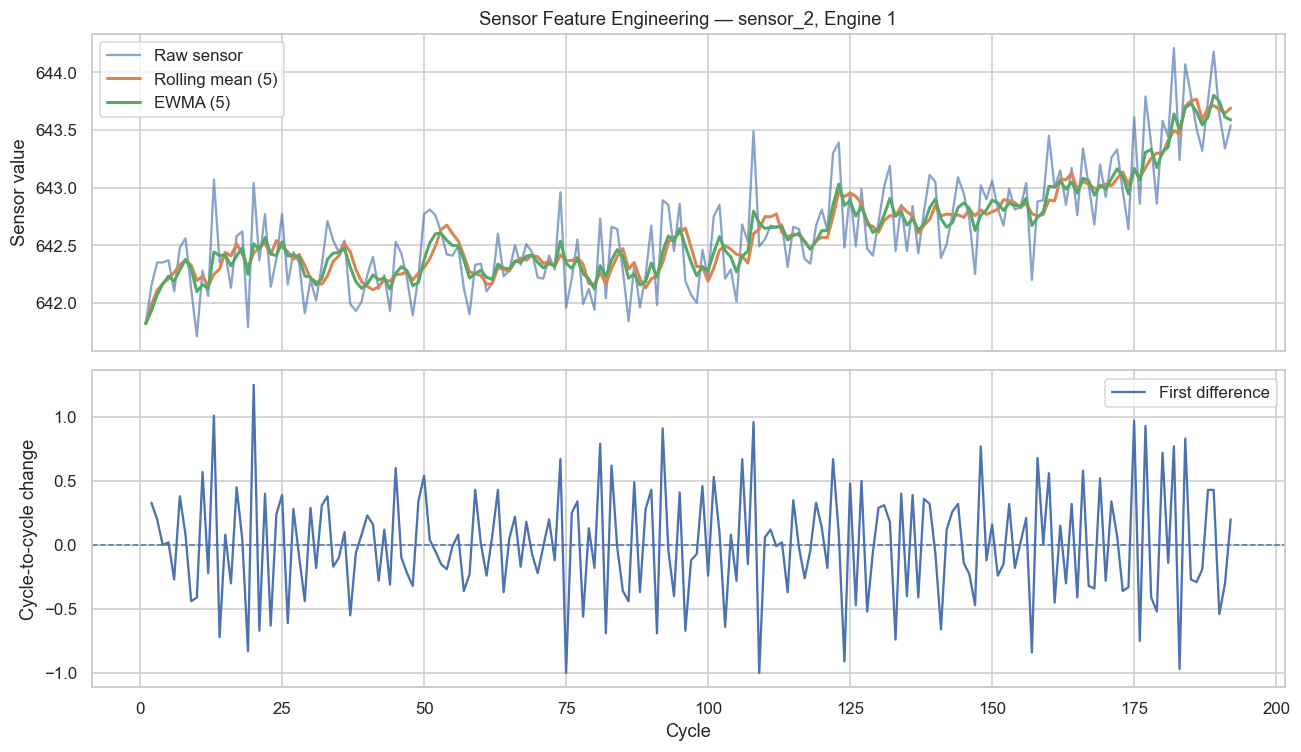

In [5]:
def add_sensor_features(data, sensors):
    data = data.sort_values(["unit", "cycle"]).copy()

    for col in sensors:
        grouped = data.groupby("unit", sort=False)[col]

        data[f"{col}_rolling_mean_5"] = grouped.transform(
            lambda x: x.rolling(window=5, min_periods=1).mean()
        )
        data[f"{col}_rolling_std_5"] = grouped.transform(
            lambda x: x.rolling(window=5, min_periods=2).std()
        )
        data[f"{col}_diff_1"] = grouped.diff(1)
        data[f"{col}_lag_1"] = grouped.shift(1)
        data[f"{col}_lag_3"] = grouped.shift(3)
        data[f"{col}_ewma_5"] = grouped.transform(
            lambda x: x.ewm(span=5, adjust=False).mean()
        )

    return data

train_features = add_sensor_features(train_df, sensor_columns)
test_features = add_sensor_features(test_df, sensor_columns)

engineered_feature_columns = [
    f"{sensor}_{suffix}"
    for sensor in sensor_columns
    for suffix in ["rolling_mean_5", "rolling_std_5", "diff_1", "lag_1", "lag_3", "ewma_5"]
]

print("Original sensor count:", len(sensor_columns))
print("Engineered feature count:", len(engineered_feature_columns))
print("Training shape after feature engineering:", train_features.shape)
print("Test shape after feature engineering:", test_features.shape)

display(train_features[["unit", "cycle", "sensor_2"] + [
    "sensor_2_rolling_mean_5", "sensor_2_rolling_std_5",
    "sensor_2_diff_1", "sensor_2_lag_1", "sensor_2_lag_3", "sensor_2_ewma_5"
]].head(10))

# Figure 5: original sensor and engineered rolling/EWMA features
feature_unit = int(train_df["unit"].iloc[0])
feature_sensor = "sensor_2"
feature_example = train_features[train_features["unit"] == feature_unit].sort_values("cycle")
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(feature_example["cycle"], feature_example[feature_sensor], label="Raw sensor", alpha=0.65)
axes[0].plot(feature_example["cycle"], feature_example[f"{feature_sensor}_rolling_mean_5"], label="Rolling mean (5)", linewidth=2)
axes[0].plot(feature_example["cycle"], feature_example[f"{feature_sensor}_ewma_5"], label="EWMA (5)", linewidth=2)
axes[0].set_title(f"Sensor Feature Engineering — {feature_sensor}, Engine {feature_unit}")
axes[0].set_ylabel("Sensor value")
axes[0].legend()
axes[1].plot(feature_example["cycle"], feature_example[f"{feature_sensor}_diff_1"], label="First difference")
axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_xlabel("Cycle")
axes[1].set_ylabel("Cycle-to-cycle change")
axes[1].legend()
save_show(fig, "05_sensor_feature_engineering_example.png")

## 6. Engine-level training/validation split

We reserve 20% of engine IDs for validation. Every cycle belonging to an engine remains in the same partition. The official test engines are not involved in this split.

In [6]:
all_train_units = np.array(sorted(train_df["unit"].unique()))
rng_split = np.random.default_rng(SEED)
shuffled_units = rng_split.permutation(all_train_units)
num_val_units = max(1, int(round(0.20 * len(shuffled_units))))
val_units = np.sort(shuffled_units[:num_val_units])
train_units = np.sort(shuffled_units[num_val_units:])

train_part = train_df[train_df["unit"].isin(train_units)].copy()
val_part = train_df[train_df["unit"].isin(val_units)].copy()

print("Training engines:", len(train_units))
print("Validation engines:", len(val_units))
print("Training rows:", len(train_part))
print("Validation rows:", len(val_part))
print("Engine overlap:", len(set(train_units) & set(val_units)))
assert len(set(train_units) & set(val_units)) == 0

Training engines: 80
Validation engines: 20
Training rows: 16779
Validation rows: 3852
Engine overlap: 0


## 7. Proposed algorithm — Degradation-Aware Sensor Index (DASI)

DASI ranks each sensor using three complementary properties, calculated from complete **training-partition engines only**.

### 7.1 Monotonicity

For an engine trajectory, let `N_inc` and `N_dec` be the number of positive and negative consecutive changes. We calculate:

\[
M_s = \left|\frac{N_{inc}-N_{dec}}{N_{inc}+N_{dec}+\epsilon}\right|
\]

We average this across training engines. A sensor with a mostly consistent increasing or decreasing trend receives a higher score.

### 7.2 Trendability

Each engine's trajectory is interpolated to the same normalized life-progress axis. We calculate pairwise Pearson correlations between engine curves and average their absolute values:

\[
T_s = \operatorname{mean}_{i<j} |\operatorname{corr}(x_{s,i},x_{s,j})|
\]

This measures whether different engines show similarly shaped trajectories. The absolute correlation allows a consistent increasing or decreasing direction.

### 7.3 Prognosability

We compare the average of the first few readings with the average of the final few readings for each training engine. Let `E_i` be the end-of-life mean for engine `i`:

\[
P_s = \exp\left(-\frac{\operatorname{std}(E_i)}
{|\operatorname{mean}(E_i)-\operatorname{mean}(B_i)|+\epsilon}\right)
\]

A near-constant sensor is assigned zero prognosability when its average start-to-end change is negligible.

### 7.4 Composite index and selection

\[
DASI_s = \frac{M_s + T_s + P_s}{3}
\]

We rank sensors by DASI and select the top 14. Equal weights are used as a simple initial design; they are not tuned on validation or test labels.

In [7]:
def sensor_monotonicity(values):
    values = np.asarray(values, dtype=float)
    differences = np.diff(values)
    nonzero = differences[np.abs(differences) > 1e-12]

    if len(nonzero) == 0:
        return 0.0

    n_inc = np.sum(nonzero > 0)
    n_dec = np.sum(nonzero < 0)
    return float(abs(n_inc - n_dec) / (n_inc + n_dec + 1e-12))


def sensor_prognosability(engine_curves, endpoint_window=5):
    start_values = []
    end_values = []

    for curve in engine_curves:
        curve = np.asarray(curve, dtype=float)
        if len(curve) < 2:
            continue
        k = min(endpoint_window, max(1, len(curve) // 3))
        start_values.append(float(np.mean(curve[:k])))
        end_values.append(float(np.mean(curve[-k:])))

    if len(end_values) < 3:
        return 0.0

    mean_change = abs(float(np.mean(end_values) - np.mean(start_values)))
    end_dispersion = float(np.std(end_values))

    # A sensor with no meaningful start-to-end separation is not informative here.
    if mean_change < 1e-8:
        return 0.0

    score = np.exp(-end_dispersion / (mean_change + 1e-8))
    return float(np.clip(score, 0.0, 1.0))


def sensor_trendability(engine_curves, points=50):
    aligned_curves = []

    for curve in engine_curves:
        curve = np.asarray(curve, dtype=float)
        if len(curve) < 5 or np.std(curve) < 1e-10:
            continue

        old_axis = np.linspace(0.0, 1.0, num=len(curve))
        new_axis = np.linspace(0.0, 1.0, num=points)
        aligned = np.interp(new_axis, old_axis, curve)
        aligned_curves.append(aligned)

    if len(aligned_curves) < 3:
        return 0.0

    correlations = []
    for curve_a, curve_b in combinations(aligned_curves, 2):
        if np.std(curve_a) < 1e-10 or np.std(curve_b) < 1e-10:
            continue
        corr = np.corrcoef(curve_a, curve_b)[0, 1]
        if np.isfinite(corr):
            correlations.append(abs(float(corr)))

    return float(np.mean(correlations)) if correlations else 0.0


def calculate_dasi(data, sensors, points=50):
    """Calculate DASI from the supplied engines; caller must pass training engines only."""
    rows = []
    grouped_engines = [
        group.sort_values("cycle")
        for _, group in data.groupby("unit", sort=True)
    ]

    for sensor in sensors:
        curves = [group[sensor].to_numpy(dtype=float) for group in grouped_engines]
        curves = [curve for curve in curves if len(curve) >= 5]

        if len(curves) < 3:
            rows.append({
                "Sensor": sensor, "Monotonicity": 0.0,
                "Trendability": 0.0, "Prognosability": 0.0, "DASI": 0.0
            })
            continue

        monotonicity = float(np.mean([sensor_monotonicity(curve) for curve in curves]))
        trendability = sensor_trendability(curves, points=points)
        prognosability = sensor_prognosability(curves)
        dasi = (monotonicity + trendability + prognosability) / 3.0

        rows.append({
            "Sensor": sensor,
            "Monotonicity": monotonicity,
            "Trendability": trendability,
            "Prognosability": prognosability,
            "DASI": dasi
        })

    return pd.DataFrame(rows).sort_values("DASI", ascending=False).reset_index(drop=True)

# IMPORTANT: calculate DASI only from the training engine partition.
sensor_scores = calculate_dasi(train_part, sensor_columns)

dasi_sensors = sensor_scores.head(TOP_K_SENSORS)["Sensor"].tolist()

# Original 14-sensor selection used in the V2 GRU notebook.
baseline_sensors = [
    "sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_8", "sensor_9",
    "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
    "sensor_17", "sensor_20", "sensor_21"
]

assert all(sensor in sensor_columns for sensor in baseline_sensors)
assert len(dasi_sensors) == TOP_K_SENSORS

print("Original V2 sensors:", baseline_sensors)
print("DASI-selected sensors:", dasi_sensors)
print("\\nDASI ranking:")
display(sensor_scores.round(4))

sensor_scores.to_csv(OUTPUT_DIR / "dasi_sensor_scores.csv", index=False)

Original V2 sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
DASI-selected sensors: ['sensor_11', 'sensor_4', 'sensor_12', 'sensor_7', 'sensor_15', 'sensor_20', 'sensor_21', 'sensor_2', 'sensor_17', 'sensor_3', 'sensor_8', 'sensor_13', 'sensor_6', 'sensor_9']
\nDASI ranking:


,Sensor,Monotonicity,Trendability,Prognosability,DASI
0,sensor_11,0.0381,0.8685,0.9362,0.6143
1,sensor_4,0.0352,0.8273,0.9364,0.5996
2,sensor_12,0.0385,0.8326,0.8892,0.5868
3,sensor_7,0.0449,0.7960,0.8906,0.5772
4,sensor_15,0.0376,0.7491,0.9241,0.5703
5,sensor_20,0.0358,0.7179,0.9156,0.5564
6,sensor_21,0.0354,0.7222,0.9100,0.5558
7,sensor_2,0.0376,0.6769,0.9125,0.5423
8,sensor_17,0.0322,0.6536,0.8823,0.5227
9,sensor_3,0.0355,0.6155,0.8756,0.5088


## 8. DASI visualizations for the presentation

Use these charts to explain which sensors the algorithm ranks highly and why. The ranking is learned from the training-engine sensor trajectories, not from validation/test outcomes.

Saved: outputs_DA_GRU\figures\06_dasi_sensor_ranking.png


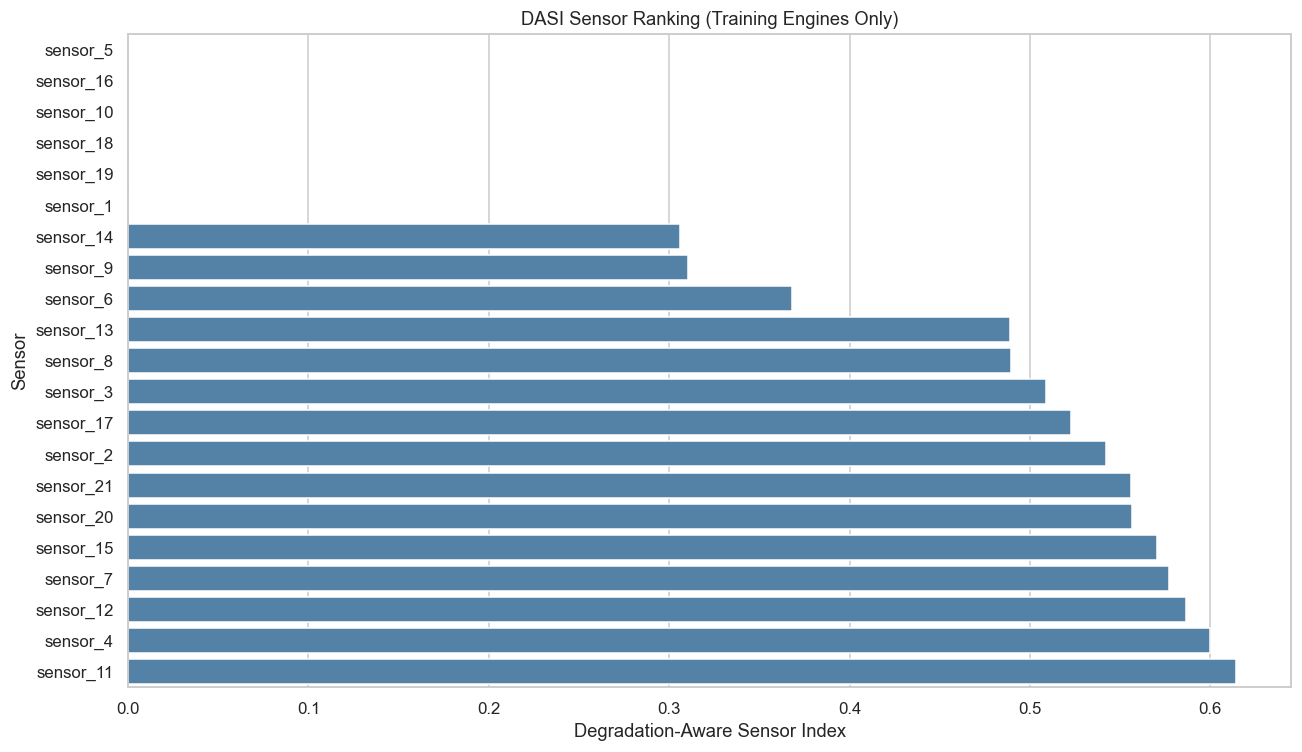

Saved: outputs_DA_GRU\figures\07_dasi_component_heatmap.png


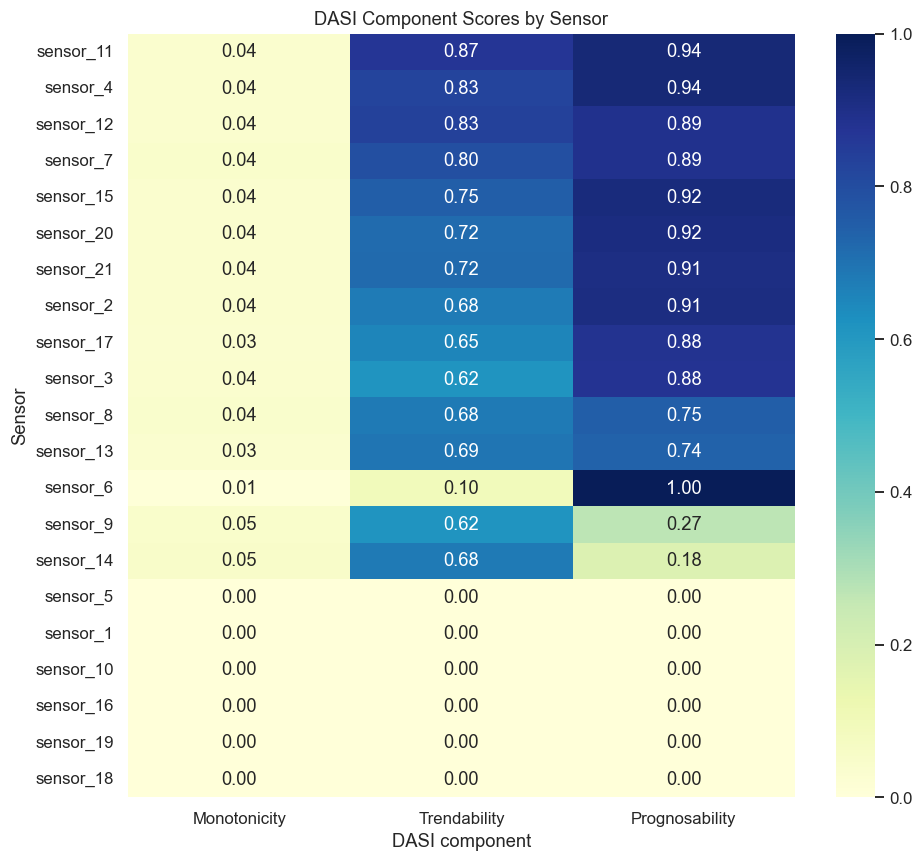

Saved: outputs_DA_GRU\figures\08_sensor_selection_comparison.png


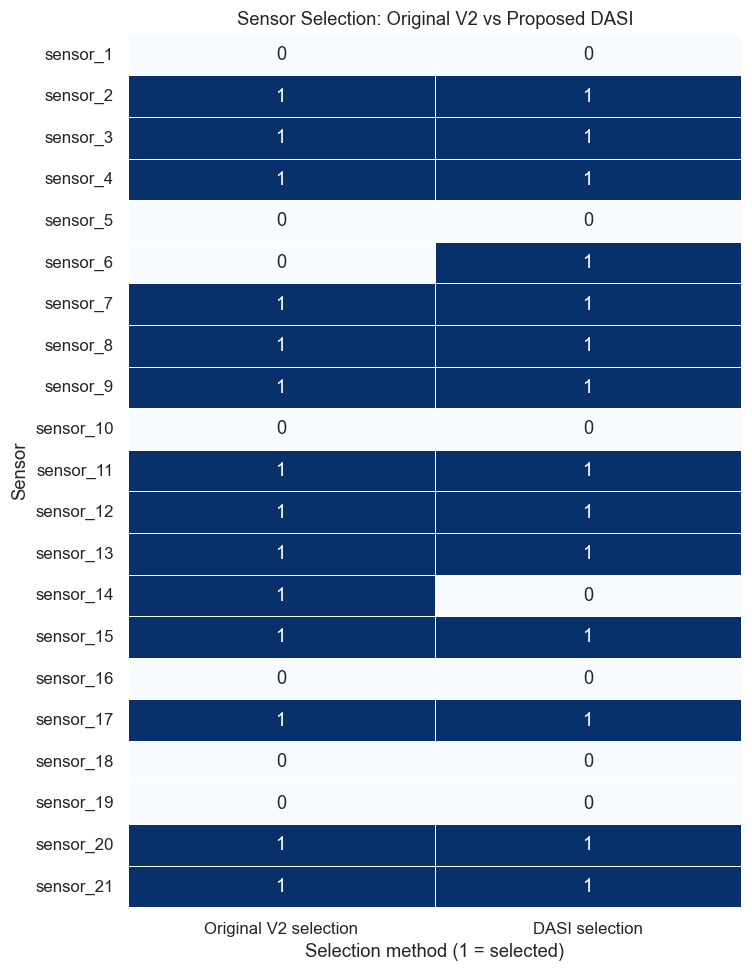

Overlap between selections: 13 / 14
Only in DASI: ['sensor_6']
Only in original V2: ['sensor_14']
Saved: outputs_DA_GRU\figures\08b_dasi_selected_sensor_life_progression.png


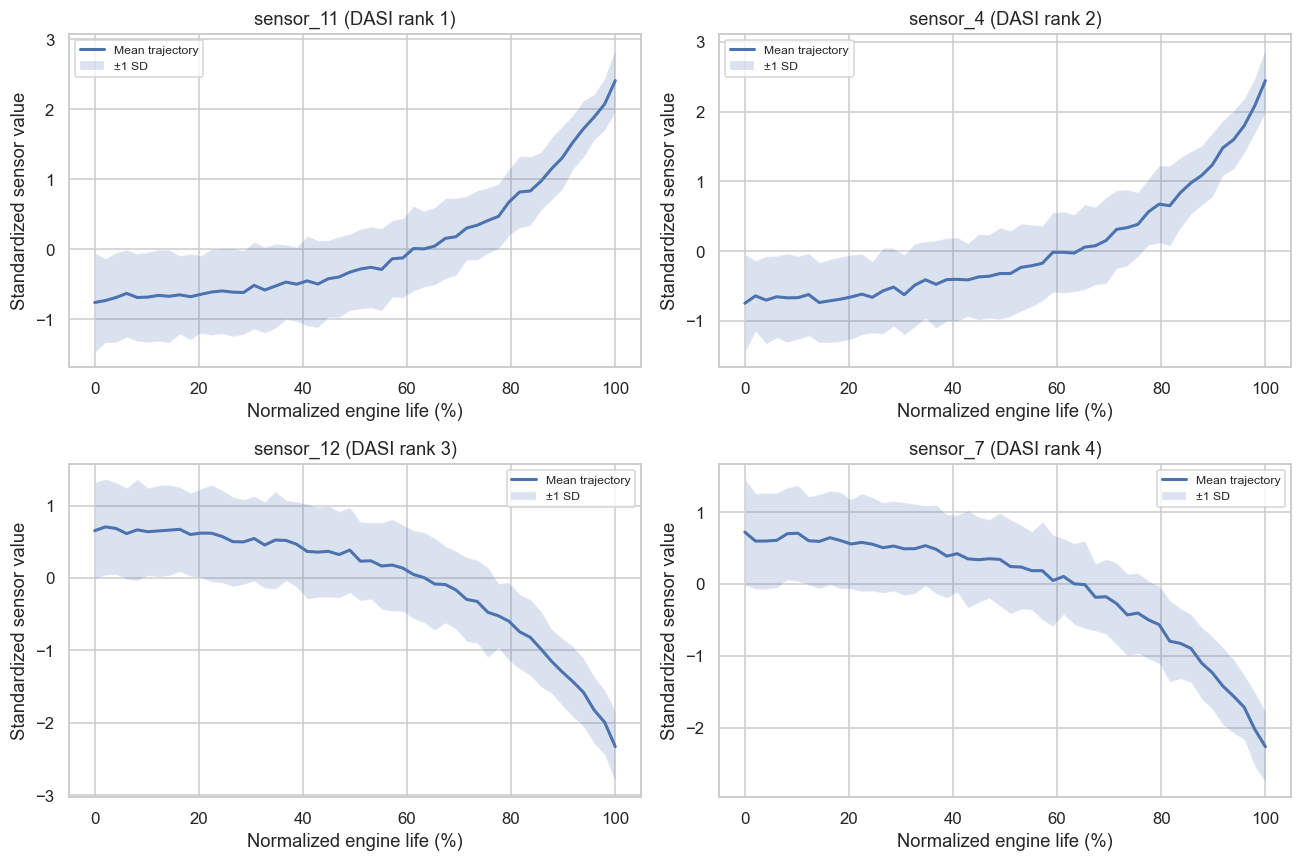

In [8]:
# Figure 6: full sensor ranking by DASI
fig, ax = plt.subplots(figsize=(12, 7))
plot_scores = sensor_scores.sort_values("DASI", ascending=True)
sns.barplot(data=plot_scores, x="DASI", y="Sensor", color="steelblue", ax=ax)
ax.set_title("DASI Sensor Ranking (Training Engines Only)")
ax.set_xlabel("Degradation-Aware Sensor Index")
ax.set_ylabel("Sensor")
save_show(fig, "06_dasi_sensor_ranking.png")

# Figure 7: three component scores for each sensor
component_matrix = sensor_scores.set_index("Sensor")[
    ["Monotonicity", "Trendability", "Prognosability"]
]
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(component_matrix, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax)
ax.set_title("DASI Component Scores by Sensor")
ax.set_xlabel("DASI component")
ax.set_ylabel("Sensor")
save_show(fig, "07_dasi_component_heatmap.png")

# Figure 8: compare original V2 selection with DASI selection
selection_comparison = pd.DataFrame({
    "Sensor": sensor_columns,
    "Original V2 selection": [int(s in baseline_sensors) for s in sensor_columns],
    "DASI selection": [int(s in dasi_sensors) for s in sensor_columns]
}).set_index("Sensor")

fig, ax = plt.subplots(figsize=(7, 9))
sns.heatmap(selection_comparison, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5, ax=ax)
ax.set_title("Sensor Selection: Original V2 vs Proposed DASI")
ax.set_xlabel("Selection method (1 = selected)")
ax.set_ylabel("Sensor")
save_show(fig, "08_sensor_selection_comparison.png")

print("Overlap between selections:", len(set(baseline_sensors) & set(dasi_sensors)), "/", TOP_K_SENSORS)
print("Only in DASI:", sorted(set(dasi_sensors) - set(baseline_sensors)))
print("Only in original V2:", sorted(set(baseline_sensors) - set(dasi_sensors)))

# Figure 8b: average degradation trajectories for the top four DASI sensors.
# Each engine is resampled to 50 points on normalized life progress.
top_curve_sensors = sensor_scores.head(4)["Sensor"].tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, sensor in zip(axes.flat, top_curve_sensors):
    sensor_mean = float(train_part[sensor].mean())
    sensor_std = float(train_part[sensor].std() + 1e-8)
    aligned = []

    for _, engine in train_part.groupby("unit"):
        engine = engine.sort_values("cycle")
        values = engine[sensor].to_numpy(dtype=float)
        if len(values) < 5:
            continue
        z_values = (values - sensor_mean) / sensor_std
        aligned.append(np.interp(
            np.linspace(0, 1, 50),
            np.linspace(0, 1, len(z_values)),
            z_values
        ))

    aligned = np.asarray(aligned)
    mean_curve = aligned.mean(axis=0)
    std_curve = aligned.std(axis=0)
    life_progress = np.linspace(0, 100, 50)
    ax.plot(life_progress, mean_curve, linewidth=2, label="Mean trajectory")
    ax.fill_between(life_progress, mean_curve - std_curve, mean_curve + std_curve, alpha=0.2, label="±1 SD")
    ax.set_title(f"{sensor} (DASI rank {sensor_scores.index[sensor_scores['Sensor'] == sensor][0] + 1})")
    ax.set_xlabel("Normalized engine life (%)")
    ax.set_ylabel("Standardized sensor value")
    ax.legend(fontsize=8)

save_show(fig, "08b_dasi_selected_sensor_life_progression.png")


## 9. Build comparable validation examples

For every held-out validation engine, create observations at target RUL points 20, 50, 80 and 110 cycles (where enough history exists). Each example uses only the engine's history up to that cutoff. Both GRU experiments use exactly these same examples.

The training windows are built from training engines only, with the target attached to the final cycle in each 30-cycle window.

Validation examples: 79
Validation engines represented: 20 / 20
Validation target distribution:


,actual_RUL
count,79.00000
mean,64.43038
std,33.57910
min,20.00000
25%,35.00000
50%,50.00000
75%,80.00000
max,110.00000


,unit,cutoff_cycle,actual_RUL_raw,actual_RUL
0,3,159,20.0,20.0
1,3,129,50.0,50.0
2,3,99,80.0,80.0
3,3,69,110.0,110.0
4,5,249,20.0,20.0


Saved: outputs_DA_GRU\figures\09_validation_rul_stage_counts.png


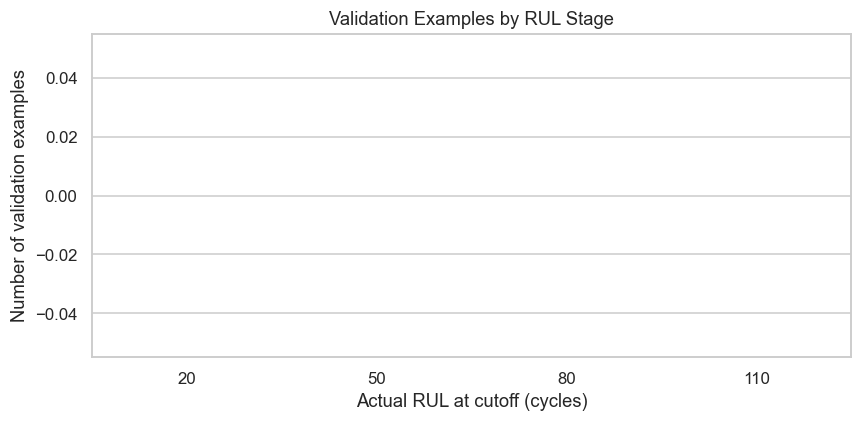

In [9]:
# Create a validation metadata table. RUL is exact here because training engines are run to failure.
validation_records = []
for unit in val_units:
    engine = val_part[val_part["unit"] == unit].sort_values("cycle")
    last_cycle = int(engine["cycle"].max())

    for target_rul in VALIDATION_RUL_POINTS:
        cutoff_cycle = last_cycle - int(target_rul)
        prefix = engine[engine["cycle"] <= cutoff_cycle]

        if len(prefix) < WINDOW_SIZE:
            continue

        validation_records.append({
            "unit": int(unit),
            "cutoff_cycle": int(cutoff_cycle),
            "actual_RUL_raw": float(target_rul),
            "actual_RUL": float(min(target_rul, RUL_CAP))
        })

val_meta = pd.DataFrame(validation_records)
if val_meta.empty:
    raise ValueError("No validation examples were created. Check WINDOW_SIZE and validation cutoffs.")

print("Validation examples:", len(val_meta))
print("Validation engines represented:", val_meta["unit"].nunique(), "/", len(val_units))
print("Validation target distribution:")
display(val_meta["actual_RUL"].describe().to_frame())
display(val_meta.head())

# Figure 9: validation sample counts across selected RUL stages
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=val_meta, x="actual_RUL", order=VALIDATION_RUL_POINTS, color="steelblue", ax=ax)
ax.set_title("Validation Examples by RUL Stage")
ax.set_xlabel("Actual RUL at cutoff (cycles)")
ax.set_ylabel("Number of validation examples")
save_show(fig, "09_validation_rul_stage_counts.png")

## 10. Sequence preparation and evaluation metrics

The imputer and scaler are fitted on unique training rows for the selected sensor set. They are then applied to validation rows. This avoids fitting preprocessing on validation data or overweighting interior cycles because they occur in many overlapping windows.

In [10]:
def make_training_sequences(data, units, feature_columns, window_size):
    X, y = [], []

    for unit in units:
        engine = data[data["unit"] == unit].sort_values("cycle")
        values = engine[feature_columns].to_numpy(dtype=np.float32)
        targets = engine["RUL"].to_numpy(dtype=np.float32)

        if len(engine) < window_size:
            continue

        for end in range(window_size - 1, len(engine)):
            X.append(values[end - window_size + 1:end + 1])
            y.append(targets[end])

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)


def make_validation_sequences(data, metadata, feature_columns, window_size):
    X, y = [], []
    used_rows = []

    for row in metadata.itertuples(index=False):
        engine = data[
            (data["unit"] == row.unit) & (data["cycle"] <= row.cutoff_cycle)
        ].sort_values("cycle")

        if len(engine) < window_size:
            continue

        values = engine[feature_columns].to_numpy(dtype=np.float32)
        X.append(values[-window_size:])
        y.append(float(row.actual_RUL))
        used_rows.append({
            "unit": int(row.unit),
            "cutoff_cycle": int(row.cutoff_cycle),
            "actual_RUL": float(row.actual_RUL)
        })

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32), pd.DataFrame(used_rows)


def nasa_score(actual, predicted):
    """NASA asymmetric score; lower is better."""
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.asarray(predicted, dtype=np.float64)
    error = predicted - actual
    penalties = np.where(error < 0, np.exp(-error / 13.0) - 1.0,
                         np.exp(error / 10.0) - 1.0)
    return float(np.sum(penalties))


def evaluate_rul(actual, predicted):
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.maximum(np.asarray(predicted, dtype=np.float64), 0.0)
    return {
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "NASA Score": nasa_score(actual, predicted)
    }


def transform_frame(frame, feature_columns, imputer, scaler):
    out = frame[["unit", "cycle", "RUL"]].copy() if "RUL" in frame.columns else frame[["unit", "cycle"]].copy()
    values = imputer.transform(frame[feature_columns])
    values = scaler.transform(values)
    for idx, col in enumerate(feature_columns):
        out[col] = values[:, idx]
    return out

## 11. Original GRU architecture (unchanged)

The model is the same plain GRU design used in V2. It has no attention module, no BiLSTM, and no additional recurrent branch.

In [11]:
class GRURegressor(nn.Module):
    def __init__(self, input_size, hidden_size=HIDDEN_SIZE,
                 num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.output = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        out, _ = self.gru(x)
        return self.output(out[:, -1, :]).squeeze(1)


def train_gru_experiment(experiment_name, feature_columns):
    """Train one GRU variant under the same split and validation protocol."""
    seed_everything(SEED)

    # Fit preprocessing only on training-partition rows, not validation rows.
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    train_imputed = imputer.fit_transform(train_part[feature_columns])
    scaler.fit(train_imputed)

    train_scaled = transform_frame(train_part, feature_columns, imputer, scaler)
    val_scaled = transform_frame(val_part, feature_columns, imputer, scaler)

    X_train, y_train = make_training_sequences(
        train_scaled, train_units, feature_columns, WINDOW_SIZE
    )
    X_val, y_val, val_meta_used = make_validation_sequences(
        val_scaled, val_meta, feature_columns, WINDOW_SIZE
    )

    if len(X_train) == 0 or len(X_val) == 0:
        raise ValueError(f"No sequence data available for {experiment_name}.")

    # Scale targets using training targets only.
    y_mean = float(y_train.mean())
    y_std = float(y_train.std() + 1e-8)
    y_train_scaled = (y_train - y_mean) / y_std

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train_scaled, dtype=torch.float32)
    )
    loader_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        generator=loader_generator, num_workers=0
    )

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32, device=device)
    model = GRURegressor(input_size=len(feature_columns)).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3
    )
    loss_function = nn.SmoothL1Loss()

    best_rmse = float("inf")
    best_state = None
    best_epoch = 0
    patience_counter = 0
    history = []

    print(f"\\nTraining: {experiment_name}")
    print("Input shape:", X_train.shape, "| Validation shape:", X_val.shape)

    for epoch in range(1, MAX_EPOCHS + 1):
        lr_used = float(optimizer.param_groups[0]["lr"])
        model.train()
        running_loss = 0.0

        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad(set_to_none=True)
            predictions = model(batch_X)
            loss = loss_function(predictions, batch_y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += float(loss.item())

        train_loss = running_loss / max(len(train_loader), 1)

        model.eval()
        with torch.no_grad():
            val_scaled_predictions = model(X_val_tensor).cpu().numpy()

        val_predictions = np.clip(val_scaled_predictions * y_std + y_mean, 0.0, RUL_CAP)
        val_rmse = float(np.sqrt(mean_squared_error(y_val, val_predictions)))
        scheduler.step(val_rmse)

        history.append({"epoch": epoch, "train_loss": train_loss, "val_rmse": val_rmse, "lr_used": lr_used})

        if val_rmse < best_rmse:
            best_rmse = val_rmse
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
                f"Train loss: {train_loss:.4f} | Val RMSE: {val_rmse:.3f}"
            )

        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch}; best epoch = {best_epoch}")
            break

    if best_state is None:
        raise RuntimeError(f"Training failed to produce a checkpoint for {experiment_name}.")

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        val_scaled_predictions = model(X_val_tensor).cpu().numpy()

    val_predictions = np.clip(val_scaled_predictions * y_std + y_mean, 0.0, RUL_CAP)
    scores = evaluate_rul(y_val, val_predictions)

    return {
        "name": experiment_name,
        "features": list(feature_columns),
        "model": model,
        "imputer": imputer,
        "scaler": scaler,
        "y_mean": y_mean,
        "y_std": y_std,
        "best_epoch": best_epoch,
        "history": pd.DataFrame(history),
        "X_val": X_val,
        "y_val": y_val,
        "val_predictions": val_predictions,
        "val_meta": val_meta_used,
        "metrics": scores,
        "train_sequence_shape": X_train.shape
    }

## 12. Run the controlled comparison: original GRU vs DASI-GRU

Only the sensor-selection method changes:

- **Baseline GRU:** the 14 sensor channels hard-coded in the V2 notebook.
- **Proposed DASI-GRU:** the top 14 sensors selected by DASI.

Both models use the same GRU class, 30-cycle windows, engine split, validation cutoffs, optimizer, early stopping rule and metrics.

In [12]:
baseline_result = train_gru_experiment("Original V2 GRU", baseline_sensors)
dasi_result = train_gru_experiment("Proposed DASI-GRU", dasi_sensors)

validation_results = pd.DataFrame([
    {"Model": baseline_result["name"], **baseline_result["metrics"]},
    {"Model": dasi_result["name"], **dasi_result["metrics"]}
]).sort_values("RMSE").reset_index(drop=True)

print("Validation results — same validation examples for both models:")
display(validation_results.round(4))

improvement = {
    metric: baseline_result["metrics"][metric] - dasi_result["metrics"][metric]
    for metric in ["RMSE", "MAE", "NASA Score"]
}
print("\\nBaseline minus DASI (positive means DASI improved):")
print(pd.Series(improvement).round(4))

validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)

\nTraining: Original V2 GRU
Input shape: (14459, 30, 14) | Validation shape: (79, 30, 14)
Epoch 01/50 | Train loss: 0.1216 | Val RMSE: 18.761
Epoch 05/50 | Train loss: 0.0443 | Val RMSE: 18.207
Epoch 10/50 | Train loss: 0.0364 | Val RMSE: 16.454
Early stopping at epoch 10; best epoch = 2
\nTraining: Proposed DASI-GRU
Input shape: (14459, 30, 14) | Validation shape: (79, 30, 14)
Epoch 01/50 | Train loss: 0.1194 | Val RMSE: 19.893
Epoch 05/50 | Train loss: 0.0468 | Val RMSE: 19.175
Epoch 10/50 | Train loss: 0.0352 | Val RMSE: 17.201
Early stopping at epoch 10; best epoch = 2
Validation results — same validation examples for both models:


,Model,RMSE,MAE,NASA Score
0,Original V2 GRU,15.2603,10.5135,817.6382
1,Proposed DASI-GRU,16.3980,11.8274,938.0568


\nBaseline minus DASI (positive means DASI improved):
RMSE           -1.1377
MAE            -1.3139
NASA Score   -120.4186
dtype: float64


## 13. Training and validation visualizations

The plots show convergence and prediction quality. Use the metric table and the actual-vs-predicted plot in the presentation; report the values produced by your actual run, not expected values.

Saved: outputs_DA_GRU\figures\10_training_curves_and_validation_metrics.png


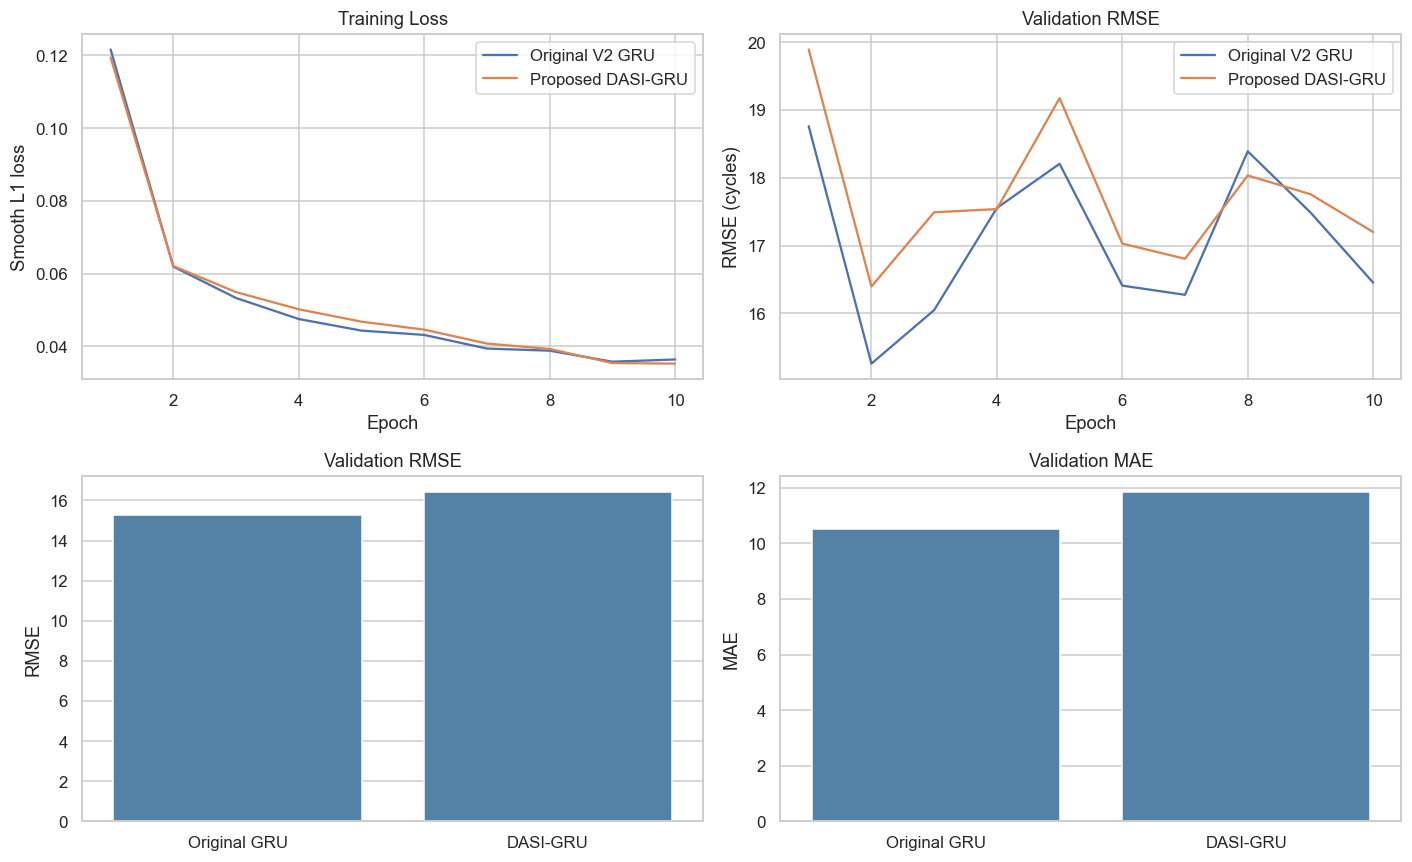

Saved: outputs_DA_GRU\figures\11_dasi_gru_validation_actual_vs_predicted.png


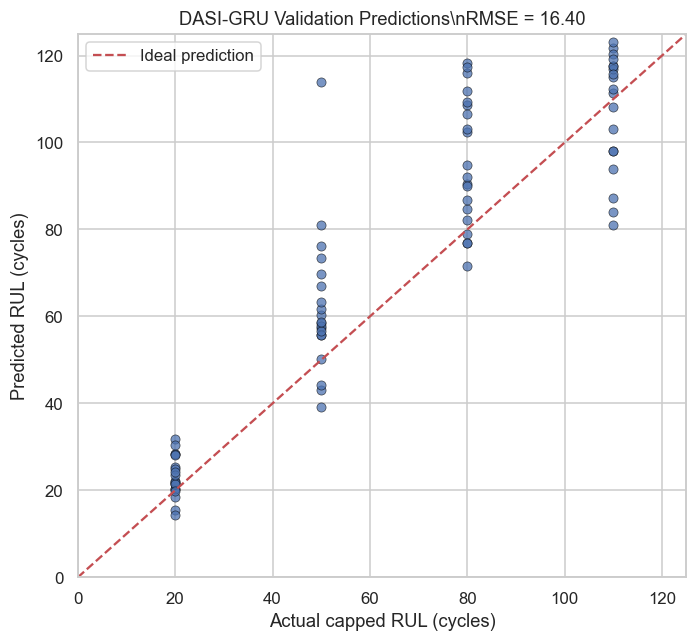

Saved: outputs_DA_GRU\figures\12_dasi_gru_validation_error_distribution.png


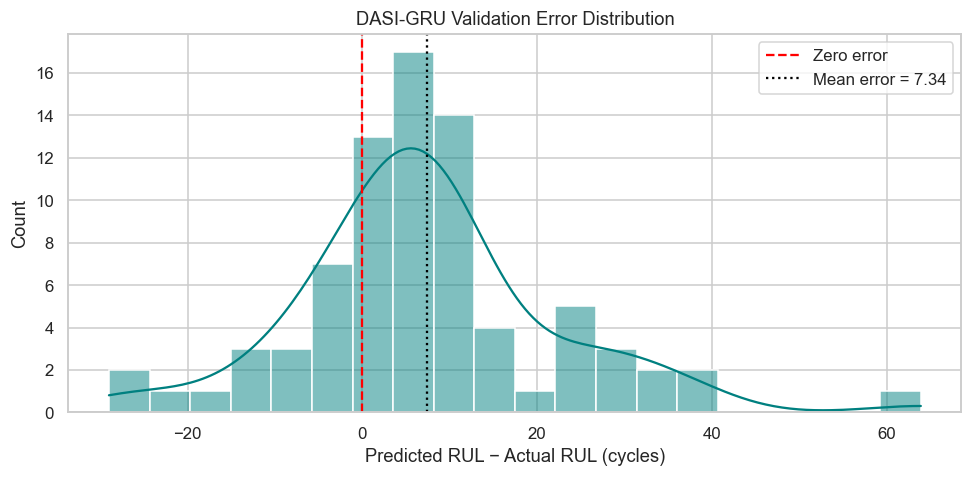

Saved: outputs_DA_GRU\figures\13_dasi_gru_error_by_rul_stage.png


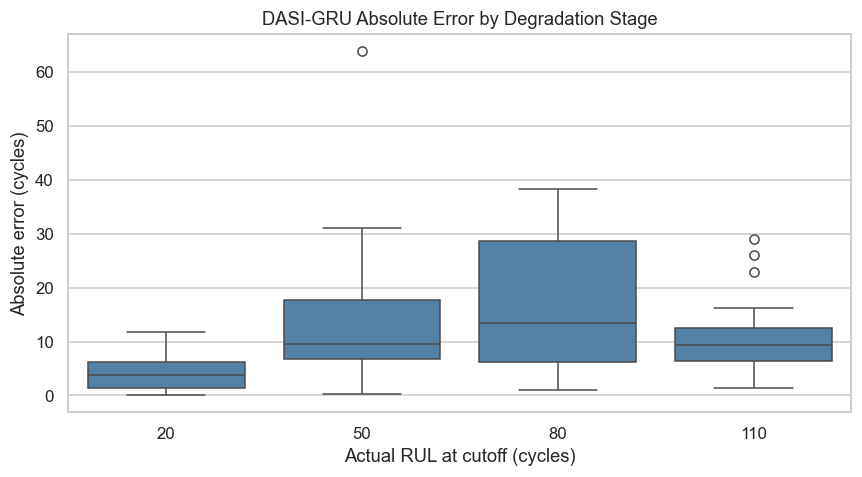

In [13]:
# Figure 10: learning curves for both models
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for result, color_label in [(baseline_result, "Original V2 GRU"), (dasi_result, "Proposed DASI-GRU")]:
    hist = result["history"]
    axes[0, 0].plot(hist["epoch"], hist["train_loss"], label=color_label)
    axes[0, 1].plot(hist["epoch"], hist["val_rmse"], label=color_label)

axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Smooth L1 loss")
axes[0, 0].legend()

axes[0, 1].set_title("Validation RMSE")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("RMSE (cycles)")
axes[0, 1].legend()

metric_names = ["RMSE", "MAE", "NASA Score"]
for ax, metric in zip(axes[1], metric_names[:2]):
    values = [baseline_result["metrics"][metric], dasi_result["metrics"][metric]]
    sns.barplot(x=["Original GRU", "DASI-GRU"], y=values, color="steelblue", ax=ax)
    ax.set_title(f"Validation {metric}")
    ax.set_ylabel(metric)

save_show(fig, "10_training_curves_and_validation_metrics.png")

# Figure 11: validation actual vs predicted (proposed DASI-GRU)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(dasi_result["y_val"], dasi_result["val_predictions"], alpha=0.75, edgecolor="black", linewidth=0.4)
ax.plot([0, RUL_CAP], [0, RUL_CAP], "r--", label="Ideal prediction")
ax.set_xlim(0, RUL_CAP)
ax.set_ylim(0, RUL_CAP)
ax.set_xlabel("Actual capped RUL (cycles)")
ax.set_ylabel("Predicted RUL (cycles)")
ax.set_title(f"DASI-GRU Validation Predictions\\nRMSE = {dasi_result['metrics']['RMSE']:.2f}")
ax.legend()
save_show(fig, "11_dasi_gru_validation_actual_vs_predicted.png")

# Figure 12: validation residual distribution
val_error = dasi_result["val_predictions"] - dasi_result["y_val"]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(val_error, bins=20, kde=True, color="teal", ax=ax)
ax.axvline(0, color="red", linestyle="--", label="Zero error")
ax.axvline(np.mean(val_error), color="black", linestyle=":", label=f"Mean error = {np.mean(val_error):.2f}")
ax.set_title("DASI-GRU Validation Error Distribution")
ax.set_xlabel("Predicted RUL − Actual RUL (cycles)")
ax.set_ylabel("Count")
ax.legend()
save_show(fig, "12_dasi_gru_validation_error_distribution.png")

# Figure 13: error by RUL stage
val_plot = dasi_result["val_meta"].copy()
val_plot["predicted_RUL"] = dasi_result["val_predictions"]
val_plot["absolute_error"] = (val_plot["predicted_RUL"] - val_plot["actual_RUL"]).abs()
val_plot["RUL_stage"] = val_plot["actual_RUL"].astype(int).astype(str)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(
    data=val_plot, x="RUL_stage", y="absolute_error",
    order=[str(x) for x in VALIDATION_RUL_POINTS], color="steelblue", ax=ax
)
ax.set_title("DASI-GRU Absolute Error by Degradation Stage")
ax.set_xlabel("Actual RUL at cutoff (cycles)")
ax.set_ylabel("Absolute error (cycles)")
save_show(fig, "13_dasi_gru_error_by_rul_stage.png")

## 14. Official test evaluation (after model selection)

After comparing validation performance, we refit both variants from scratch using all official training engines. Each model is trained for the number of epochs selected by its own validation run. The final test prediction for each engine uses its latest 30 observed cycles.

The primary comparison uses capped test RUL, consistent with the training target. Raw-RUL metrics are also shown as supplementary information.

In [14]:
def make_final_training_sequences(data, feature_columns, window_size):
    return make_training_sequences(
        data=data,
        units=sorted(data["unit"].unique()),
        feature_columns=feature_columns,
        window_size=window_size
    )


def make_official_test_sequences(data, units, feature_columns, window_size):
    X = []
    used_units = []

    for unit in units:
        engine = data[data["unit"] == unit].sort_values("cycle")
        values = engine[feature_columns].to_numpy(dtype=np.float32)
        if len(values) < window_size:
            raise ValueError(f"Test engine {unit} has only {len(values)} cycles (< {window_size}).")
        X.append(values[-window_size:])
        used_units.append(int(unit))

    return np.asarray(X, dtype=np.float32), used_units


def fit_final_model_and_test(result, feature_columns):
    """Refit the selected sensor configuration on all official training engines."""
    seed_everything(SEED)

    final_imputer = SimpleImputer(strategy="median")
    final_scaler = StandardScaler()

    train_imputed = final_imputer.fit_transform(train_df[feature_columns])
    final_scaler.fit(train_imputed)

    train_scaled = transform_frame(train_df, feature_columns, final_imputer, final_scaler)
    test_frame_for_transform = test_df.copy()
    # A dummy RUL column is not needed for test sequences.
    test_scaled = transform_frame(test_frame_for_transform, feature_columns, final_imputer, final_scaler)

    X_full, y_full = make_final_training_sequences(train_scaled, feature_columns, WINDOW_SIZE)
    test_units_sorted = sorted(test_df["unit"].unique())
    X_test, used_test_units = make_official_test_sequences(
        test_scaled, test_units_sorted, feature_columns, WINDOW_SIZE
    )

    y_mean = float(y_full.mean())
    y_std = float(y_full.std() + 1e-8)
    y_full_scaled = (y_full - y_mean) / y_std

    dataset = TensorDataset(
        torch.tensor(X_full, dtype=torch.float32),
        torch.tensor(y_full_scaled, dtype=torch.float32)
    )
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED), num_workers=0
    )

    final_model = GRURegressor(input_size=len(feature_columns)).to(device)
    optimizer = torch.optim.Adam(
        final_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    loss_function = nn.SmoothL1Loss()

    epochs_to_train = max(1, int(result["best_epoch"]))
    # Replay the learning-rate values used up to the selected validation epoch.
    lr_schedule = result["history"]["lr_used"].to_numpy()[:epochs_to_train]
    for epoch in range(1, epochs_to_train + 1):
        for group in optimizer.param_groups:
            group["lr"] = float(lr_schedule[epoch - 1])
        final_model.train()
        total_loss = 0.0
        for batch_X, batch_y in loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            optimizer.zero_grad(set_to_none=True)
            predictions = final_model(batch_X)
            loss = loss_function(predictions, batch_y)
            loss.backward()
            nn.utils.clip_grad_norm_(final_model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += float(loss.item())

        if epoch == 1 or epoch == epochs_to_train or epoch % 10 == 0:
            print(f"{result['name']} | final refit epoch {epoch}/{epochs_to_train} | loss={total_loss / len(loader):.4f}")

    final_model.eval()
    with torch.no_grad():
        X_test_tensor = torch.tensor(X_test, dtype=torch.float32, device=device)
        test_scaled_predictions = final_model(X_test_tensor).cpu().numpy()

    test_predictions = np.clip(test_scaled_predictions * y_std + y_mean, 0.0, RUL_CAP)

    # C-MAPSS RUL_FD001 order corresponds to ascending test engine IDs.
    test_rul_map = dict(zip(test_units_sorted, rul_df["RUL"].astype(float).to_numpy()))
    test_actual_raw = np.asarray([test_rul_map[unit] for unit in used_test_units], dtype=float)
    test_actual_capped = np.minimum(test_actual_raw, RUL_CAP)

    return {
        "model": final_model,
        "imputer": final_imputer,
        "scaler": final_scaler,
        "target_mean": y_mean,
        "target_std": y_std,
        "test_units": used_test_units,
        "test_actual_raw": test_actual_raw,
        "test_actual_capped": test_actual_capped,
        "test_predictions": test_predictions,
        "test_metrics_capped": evaluate_rul(test_actual_capped, test_predictions),
        "test_metrics_raw": evaluate_rul(test_actual_raw, test_predictions),
        "epochs": epochs_to_train
    }


baseline_test = fit_final_model_and_test(baseline_result, baseline_sensors)
dasi_test = fit_final_model_and_test(dasi_result, dasi_sensors)

final_test_comparison = pd.DataFrame([
    {"Model": "Original V2 GRU", **baseline_test["test_metrics_capped"]},
    {"Model": "Proposed DASI-GRU", **dasi_test["test_metrics_capped"]}
]).sort_values("RMSE").reset_index(drop=True)

print("Official test comparison (capped RUL; primary):")
display(final_test_comparison.round(4))

raw_test_comparison = pd.DataFrame([
    {"Model": "Original V2 GRU", **baseline_test["test_metrics_raw"]},
    {"Model": "Proposed DASI-GRU", **dasi_test["test_metrics_raw"]}
])
print("Official test comparison (raw RUL; supplementary):")
display(raw_test_comparison.round(4))

final_test_comparison.to_csv(OUTPUT_DIR / "official_test_comparison_capped.csv", index=False)
raw_test_comparison.to_csv(OUTPUT_DIR / "official_test_comparison_raw.csv", index=False)

Original V2 GRU | final refit epoch 1/2 | loss=0.1077
Original V2 GRU | final refit epoch 2/2 | loss=0.0543
Proposed DASI-GRU | final refit epoch 1/2 | loss=0.1096
Proposed DASI-GRU | final refit epoch 2/2 | loss=0.0561
Official test comparison (capped RUL; primary):


,Model,RMSE,MAE,NASA Score
0,Original V2 GRU,13.6512,9.5795,338.7358
1,Proposed DASI-GRU,14.0349,9.5697,424.4396


Official test comparison (raw RUL; supplementary):


,Model,RMSE,MAE,NASA Score
0,Original V2 GRU,15.0263,10.6495,377.2649
1,Proposed DASI-GRU,15.4063,10.6397,465.2594


## 15. Official test visualizations and export

These figures use official test labels. Keep them separate from validation plots in the presentation and clearly label them as final test results.

,unit,actual_RUL_raw,actual_RUL_capped,predicted_RUL,error,absolute_error
78,79,63.0,63.0,110.942856,47.942856,47.942856
44,45,114.0,114.0,68.544868,-45.455132,45.455132
92,93,85.0,85.0,40.560349,-44.439651,44.439651
26,27,66.0,66.0,107.042488,41.042488,41.042488
66,67,77.0,77.0,115.827484,38.827484,38.827484
2,3,69.0,69.0,44.088531,-24.911469,24.911469
1,2,98.0,98.0,121.694733,23.694733,23.694733
94,95,128.0,125.0,103.074600,-21.925400,21.925400
14,15,83.0,83.0,104.436333,21.436333,21.436333
72,73,131.0,125.0,105.200699,-19.799301,19.799301


Saved: outputs_DA_GRU\figures\14_official_test_predictions_and_errors.png


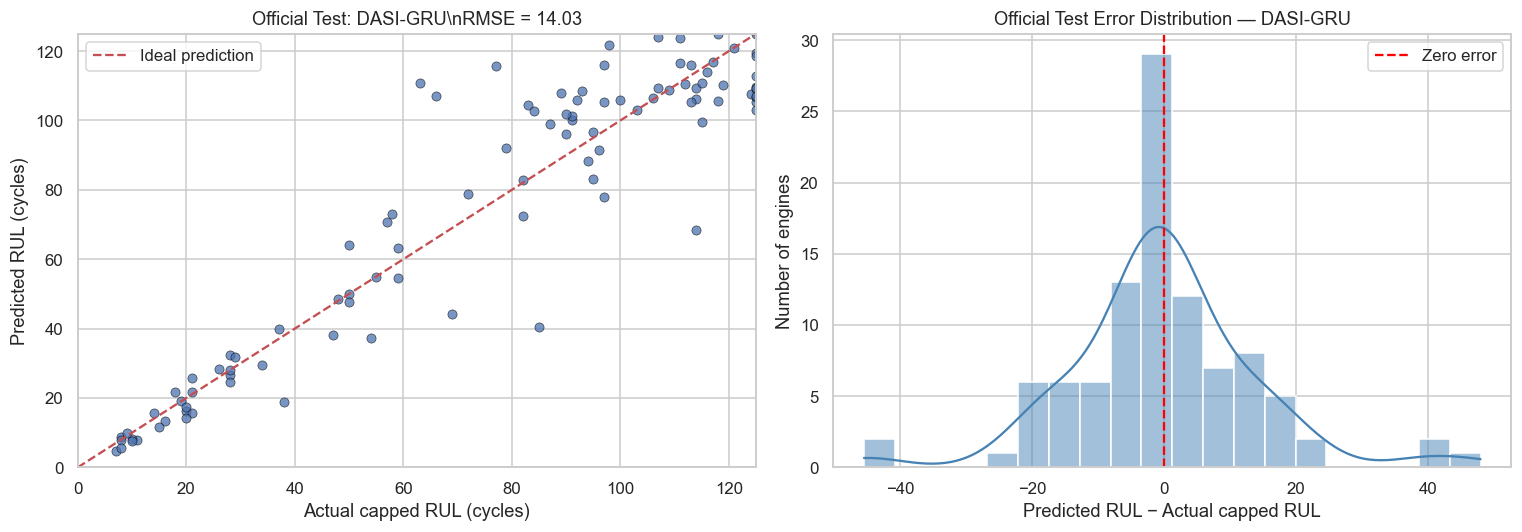

Saved: outputs_DA_GRU\figures\15_official_test_metric_comparison.png


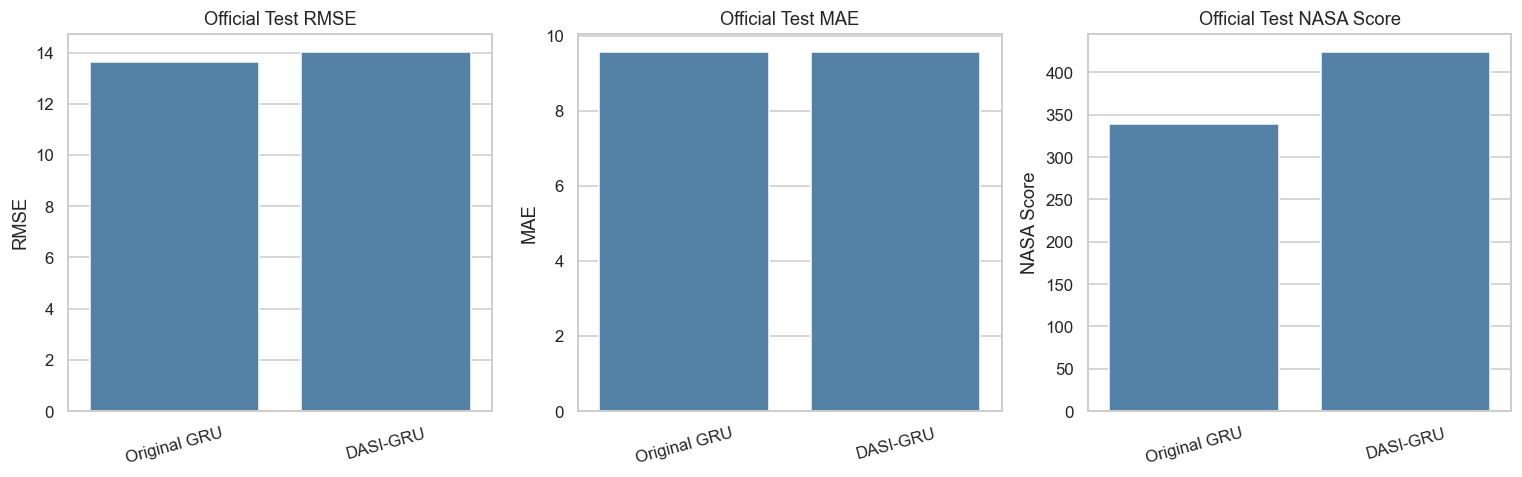

\nSaved outputs under: D:\ML_project\outputs_DA_GRU
- figures/              presentation-ready PNG plots
- dasi_sensor_scores.csv
- validation_model_comparison.csv
- official_test_comparison_capped.csv
- dasi_gru_official_test_predictions.csv
- dasi_gru_fd001.pt
- dasi_gru_preprocessing.joblib
- dasi_gru_metadata.json


In [15]:
# Test prediction table for the proposed model
test_results = pd.DataFrame({
    "unit": dasi_test["test_units"],
    "actual_RUL_raw": dasi_test["test_actual_raw"],
    "actual_RUL_capped": dasi_test["test_actual_capped"],
    "predicted_RUL": dasi_test["test_predictions"]
})
test_results["error"] = test_results["predicted_RUL"] - test_results["actual_RUL_capped"]
test_results["absolute_error"] = test_results["error"].abs()
display(test_results.sort_values("absolute_error", ascending=False).head(15))

# Figure 14: final test predictions — DASI-GRU
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(test_results["actual_RUL_capped"], test_results["predicted_RUL"], alpha=0.75, edgecolor="black", linewidth=0.4)
axes[0].plot([0, RUL_CAP], [0, RUL_CAP], "r--", label="Ideal prediction")
axes[0].set_xlim(0, RUL_CAP)
axes[0].set_ylim(0, RUL_CAP)
axes[0].set_xlabel("Actual capped RUL (cycles)")
axes[0].set_ylabel("Predicted RUL (cycles)")
axes[0].set_title(f"Official Test: DASI-GRU\\nRMSE = {dasi_test['test_metrics_capped']['RMSE']:.2f}")
axes[0].legend()

sns.histplot(test_results["error"], bins=20, kde=True, color="steelblue", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--", label="Zero error")
axes[1].set_title("Official Test Error Distribution — DASI-GRU")
axes[1].set_xlabel("Predicted RUL − Actual capped RUL")
axes[1].set_ylabel("Number of engines")
axes[1].legend()
save_show(fig, "14_official_test_predictions_and_errors.png")

# Figure 15: official test model comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, metric in zip(axes, ["RMSE", "MAE", "NASA Score"]):
    vals = [baseline_test["test_metrics_capped"][metric], dasi_test["test_metrics_capped"][metric]]
    sns.barplot(x=["Original GRU", "DASI-GRU"], y=vals, color="steelblue", ax=ax)
    ax.set_title(f"Official Test {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
save_show(fig, "15_official_test_metric_comparison.png")

# Save model artifacts, preprocessing objects, result table and run metadata.
torch.save({
    "model_state_dict": dasi_test["model"].state_dict(),
    "model_name": "DASI-GRU",
    "input_size": len(dasi_sensors),
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "window_size": WINDOW_SIZE,
    "feature_columns": dasi_sensors,
    "rul_cap": RUL_CAP,
    "subset": SUBSET
}, OUTPUT_DIR / "dasi_gru_fd001.pt")

# Save the preprocessing parameters required before model inference.
joblib.dump({
    "imputer": dasi_test["imputer"],
    "scaler": dasi_test["scaler"],
    "target_mean": dasi_test["target_mean"],
    "target_std": dasi_test["target_std"],
    "feature_columns": dasi_sensors,
    "window_size": WINDOW_SIZE,
    "rul_cap": RUL_CAP
}, OUTPUT_DIR / "dasi_gru_preprocessing.joblib")

# Save the DASI ranking and official test predictions as CSV files.
test_results.to_csv(OUTPUT_DIR / "dasi_gru_official_test_predictions.csv", index=False)

metadata = {
    "subset": SUBSET,
    "proposed_model": "DASI-GRU",
    "baseline_model": "Original V2 GRU",
    "dasi_features": dasi_sensors,
    "baseline_features": baseline_sensors,
    "window_size": WINDOW_SIZE,
    "rul_cap": RUL_CAP,
    "validation_rul_points": VALIDATION_RUL_POINTS,
    "dasi_validation_metrics": dasi_result["metrics"],
    "baseline_validation_metrics": baseline_result["metrics"],
    "dasi_official_test_metrics_capped": dasi_test["test_metrics_capped"],
    "baseline_official_test_metrics_capped": baseline_test["test_metrics_capped"],
    "best_validation_epoch_dasi": dasi_result["best_epoch"],
    "best_validation_epoch_baseline": baseline_result["best_epoch"]
}
with open(OUTPUT_DIR / "dasi_gru_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("\\nSaved outputs under:", OUTPUT_DIR.resolve())
print("- figures/              presentation-ready PNG plots")
print("- dasi_sensor_scores.csv")
print("- validation_model_comparison.csv")
print("- official_test_comparison_capped.csv")
print("- dasi_gru_official_test_predictions.csv")
print("- dasi_gru_fd001.pt")
print("- dasi_gru_preprocessing.joblib")
print("- dasi_gru_metadata.json")

## 16. How to present the method and interpret the results

### Suggested explanation

> We first implemented and compared three temporal architectures: TCN/CNN, GRU and BiLSTM. The GRU was our strongest initial baseline in our earlier experiments. We therefore retained the GRU architecture and investigated whether the manual sensor-selection step could be made systematic.
>
> We proposed a Degradation-Aware Sensor Index (DASI), which scores each sensor using monotonicity, trendability and prognosability. We rank the sensors using training engines only, select the top 14, and feed their 30-cycle sequences into the same GRU architecture. We compare this DASI-GRU against the original V2 GRU using the same engine-level validation split and cutoff points.

### What to report

- Number of sensors selected by DASI and their names.
- DASI component definitions and ranking plot.
- Validation RMSE, MAE and NASA Score for both models.
- Official test RMSE, MAE and NASA Score for both models.
- Whether DASI improves, worsens or leaves performance approximately unchanged.

### Important limitations to acknowledge

- DASI is a heuristic composite index; the equal component weights are a design choice.
- The trendability calculation uses normalized engine-life trajectories and absolute pairwise correlation.
- Results on FD001 do not establish generalization to FD002–FD004.
- The original V2 reported score came from a different validation protocol. Use the **new same-split baseline-vs-DASI comparison** generated in this notebook for a fair statement about DASI's effect.
- Do not claim that DASI improves prediction unless the measured results show it. If it does not improve, report that honestly and discuss the result.

### Presentation figure checklist

1. `01_engine_life_and_rul_distribution.png` — dataset overview.
2. `03_sensor_correlation_heatmap.png` — sensor relationships.
3. `05_sensor_feature_engineering_example.png` — feature engineering.
4. `06_dasi_sensor_ranking.png` and `07_dasi_component_heatmap.png` — proposed algorithm.
5. `08_sensor_selection_comparison.png` — original vs DASI sensor set.
6. `10_training_curves_and_validation_metrics.png` and `11_dasi_gru_validation_actual_vs_predicted.png` — validation evidence.
7. `14_official_test_predictions_and_errors.png` and `15_official_test_metric_comparison.png` — final test evidence.
